# Element: mapping the RNA cell-cycle clock to morphology

**Deliverable.** Map the transcriptional cell-cycle representation to morphological phenotypes in the Element dataset
(A549, imaging and single-cell RNA measured in the same cells), and find the correlates in OPS0077.

**The transcriptional representation** is the cycleVI clock, `cycle_position_deg` (0 to 360 degrees, one value per cell, from RNA).
In the control cells it runs: about 285 to 15 deg mostly scanpy S, 45 to 165 deg mostly G2M, 195 to 255 deg mostly G1 (section 2).

**Takeaways.**
1. **Imaging reads the RNA clock to a median of 37.5 degrees in held-out wells** (95,868 control cells; shuffled clock 77.9 deg).
   The DNA stain carries most of it (39.6 deg alone). The phospho-antibody panel is next (44.7 deg). Mitochondria, membrane,
   actin and shape are no better than the IgG isotype controls (52 to 56 deg vs 52.1), so they add nothing beyond nonspecific signal.
2. **Imaging fails on one stretch of the clock**, about 135 to 255 deg, where cells have just divided (DNA back to 2N) but
   still carry G2/M transcripts, then turn G1. Those arcs hold 19.5% of control cells and the error there is at or above the
   shuffled level. From 315 to 105 deg (75% of cells) the error is 22 to 40 deg.
3. **The largest reproducible cycle phenotypes sit in that same stretch**: at 120 to 150 deg, phospho-p38 and phospho-ERK
   intensity (up to +1.4 SD), DNA-stain texture (+0.7 SD) and pERK texture entropy rise while nuclei shrink (-0.5 SD); at
   210 to 240 deg the pattern reverses (pERK texture more uniform, larger cells and nuclei, +0.6 SD).
4. **Morphology recovers the largest measured perturbation effect but also makes false calls.** CTNNB1 knockout lowers the
   G2/M-arc fraction by 3.5 and 5.1 points (RNA) and morphology predicts 2.3 and 5.0. But it predicts shifts of +3 to +4 points
   for TGFBR2 knockout (measured -1.0 and -0.7) and +2.6 for TNFa (measured +0.2). Across 11 contrasts, Spearman rho 0.59 (p 0.056).
5. **DNA-stain texture changes the same way with DNA state in both datasets** (52 shared features: 94% same sign for 4N vs 2N,
   rho 0.67). Granularity does not agree (8 features) and scale-free cell shape does not change in either dataset. In OPS0077,
   the phase-contrast features that best mark 4N vs 2N are intensity extremes of phase-segmented objects (effect size up to 1.64,
   vs 0.74 for cell area).

Scripts: `element_cycle_morphology.py` (A to C), `element_part_d.py` (D), `element_profiles.py` (per-arc curves),
`element_cycle_figures.py` (figures). All model fitting ran on machine 1; this notebook only displays results.

In [1]:
import os, pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 70); pd.set_option('display.max_rows', 40)

def find(n):
    for r in ['reports/element_cycle_morphology', '.']:
        if os.path.exists(f'{r}/{n}'): return f'{r}/{n}'
    raise FileNotFoundError(n)

## 1. How well imaging reads the RNA clock, and which feature families carry it

**What.** Can a cell's image tell where it sits on the RNA clock, and which kinds of image features carry that information?

**How.**
* **Cells.** Control cells only (NTC and OR1I1 guides, baseline and TNFa): 95,868 cells in 12 wells.
* **Features.** 990 CellProfiler features after dropping position, background and bookkeeping columns and features missing in
  more than 15% of cells. Grouped into families by channel: DNA stain (97), antibodies against ERK, pERK, pHSP27 and p-p38 (388),
  mitochondria (97), cell membrane (97), actin (97), shape and size (20), and **IgG isotype controls (194)**.
* **The IgG isotype controls are a negative control.** They are non-binding antibodies, so their signal is background staining
  rather than specific biology. IgG still predicts the clock better than chance (52.1 vs 77.9 deg), possibly through cell size
  or nonspecific staining (not tested). A family that predicts the clock no better than IgG adds nothing beyond that.
* **Model.** Robust scaling, PCA (up to 100 components), then two ridge regressions for the sine and cosine of the clock angle.
  Leave-one-well-out: each well is predicted by a model fit on the other 11.
* **Metric.** Median angular error between predicted and RNA clock, in degrees (0 is perfect, about 90 is random for a
  uniform clock). The shuffled-clock row gives the chance level for this clock's actual distribution (77.9 deg).
  `pct_within_45deg` is the share of cells predicted within 45 degrees.
* **Reference.** In OPS0077, phase contrast predicts the 4i clock to about 30 deg. The two numbers are not directly
  comparable (different clocks, different measurement noise), so treat it only as a scale.

**Result.**
* **All features: 37.5 deg** (57.5% of cells within 45 deg).
* **The DNA stain alone is nearly as good (39.6 deg).** Without the DNA stain, the other 893 features reach 43.7 deg, so the
  rest of the image adds information but most of it overlaps with DNA.
* **The phospho-antibody panel is the only non-DNA family clearly better than IgG** (44.7 vs 52.1 deg).
* **Mitochondria (51.9), cell membrane (52.6), actin (54.4) and shape and size (55.6) sit at the IgG level.** They add nothing
  beyond the nonspecific signal that IgG also carries.
* **Three numbers (DNA content, nuclear area, cell area) already give 48.0 deg**, better than any family at the IgG level.
* The error is the same in baseline and TNFa cells (37.2 and 37.7 deg).

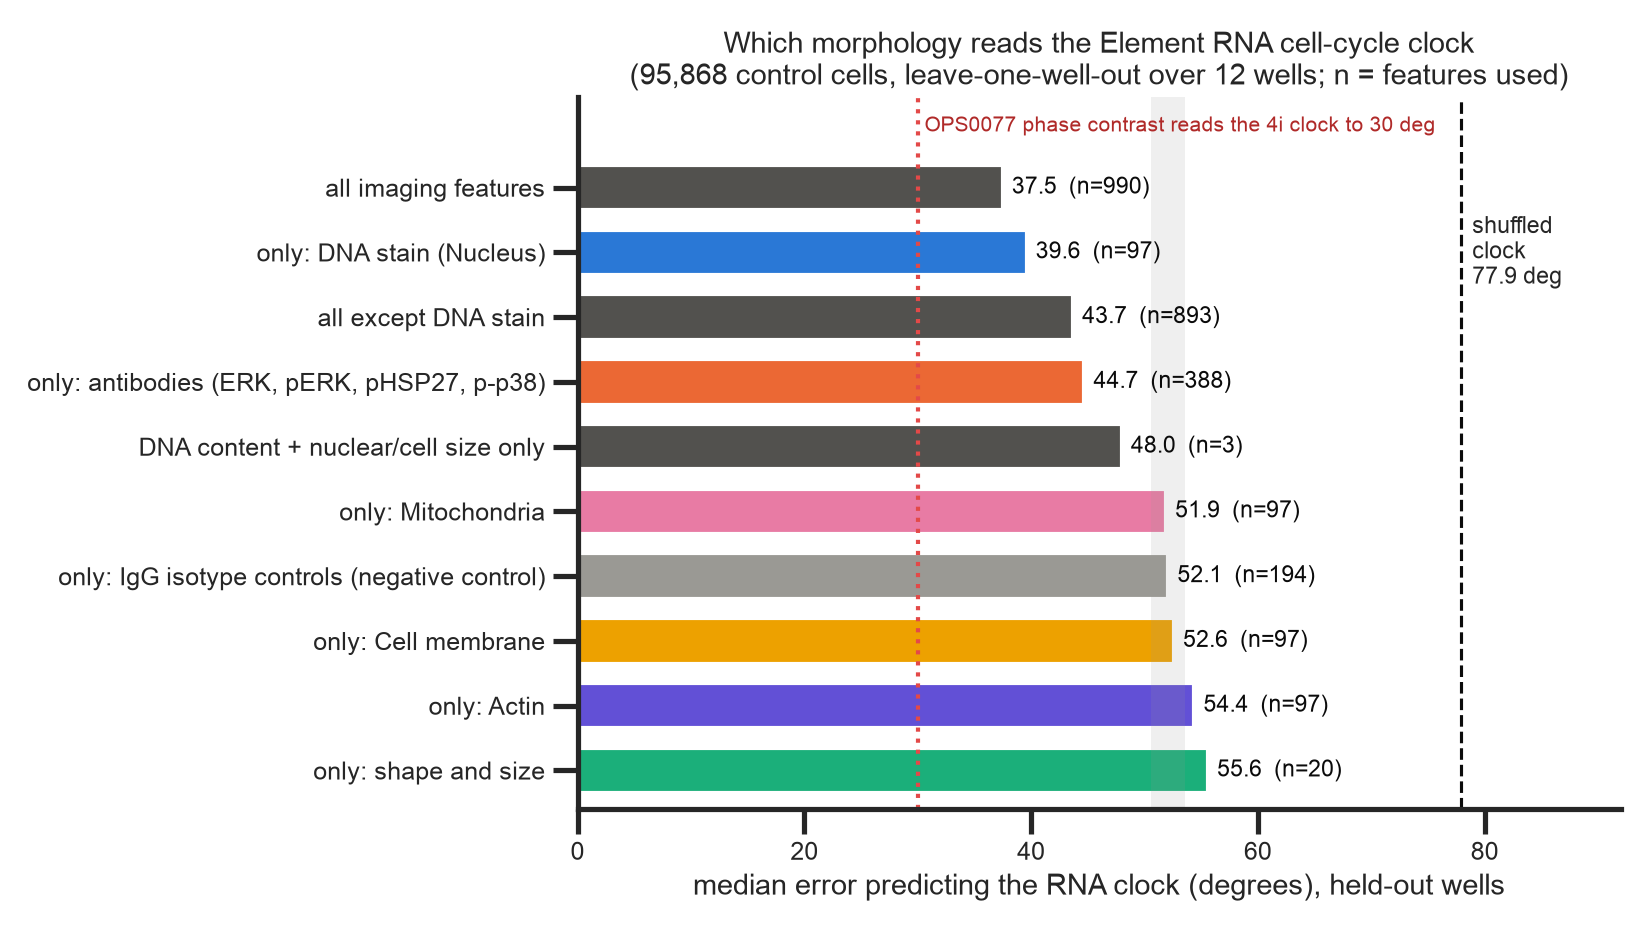

,features,n_features,median_error_deg,pct_within_45deg,mean_cos
0,all imaging features,990,37.5,57.5,0.547
1,DNA content + nuclear/cell size only,3,48.0,47.4,0.409
2,only Mitochondria,97,51.9,43.8,0.381
3,only Cell membrane,97,52.6,43.3,0.377
4,only DNA stain (Nucleus),97,39.6,55.1,0.494
5,only Actin,97,54.4,42.1,0.362
6,only IgG isotype controls (negative control),194,52.1,43.8,0.378
7,"only antibodies (ERK, pERK, pHSP27, p-p38)",388,44.7,50.3,0.465
8,only shape and size,20,55.6,40.9,0.349
9,all except DNA stain,893,43.7,51.2,0.476


In [2]:
display(Image(filename=find('fig_A_error_by_family.png')))
pd.read_csv(find('A_prediction_by_feature_family.csv'))

## 2. Where on the clock imaging fails

**What.** Is the error spread evenly around the clock, or concentrated on some arcs?

**How.** The held-out error from section 1 (all features), split into 12 arcs of 30 degrees of the RNA clock. For each arc we
also show (lower panel, baseline controls, 48,738 cells) the scanpy phase composition and the share of cells above the 4N
DNA-content threshold. DNA content is DNA-stain intensity times nuclear area, log2 relative to the well median; the threshold
(0.21) is loose, so about 20% of cells in G1 arcs sit above it. Read the line as relative, not as a true 4N fraction.

**Result.**
* **Imaging works where most cells are.** From 315 to 105 deg (scanpy S and G2M, 71,638 cells, 75% of control cells) the
  median error is 22 to 40 deg, at or near the OPS0077 phase-contrast level. The 285 deg arc is intermediate (56 deg).
* **Imaging fails from 135 to 255 deg** (18,734 cells, 19.5%): error 78 to 140 deg, at or above the shuffled level.
* **What is in that stretch.** The share of cells above the 4N threshold peaks at 105 deg (68%) and drops to 31% at 135 deg,
  so cells divide around 120 to 135 deg. From 135 to 195 deg most cells are still scanpy G2M (59 to 95%) but their DNA is back
  at 2N. From 195 to 255 deg the scanpy G1 share rises to its peak (59% at 225 deg). These are newly divided cells.
* **Why it fails, probably.** These arcs are sparse (1,031 to 2,910 baseline cells per arc vs 5,485 to 7,141 on the 315 to
  105 deg arcs), and a
  newly divided 2N cell looks much like the 2N cells at 285 to 15 deg. The ridge model is pulled toward the dense arcs. This is
  an interpretation; we did not test a model weighted toward the sparse arcs.

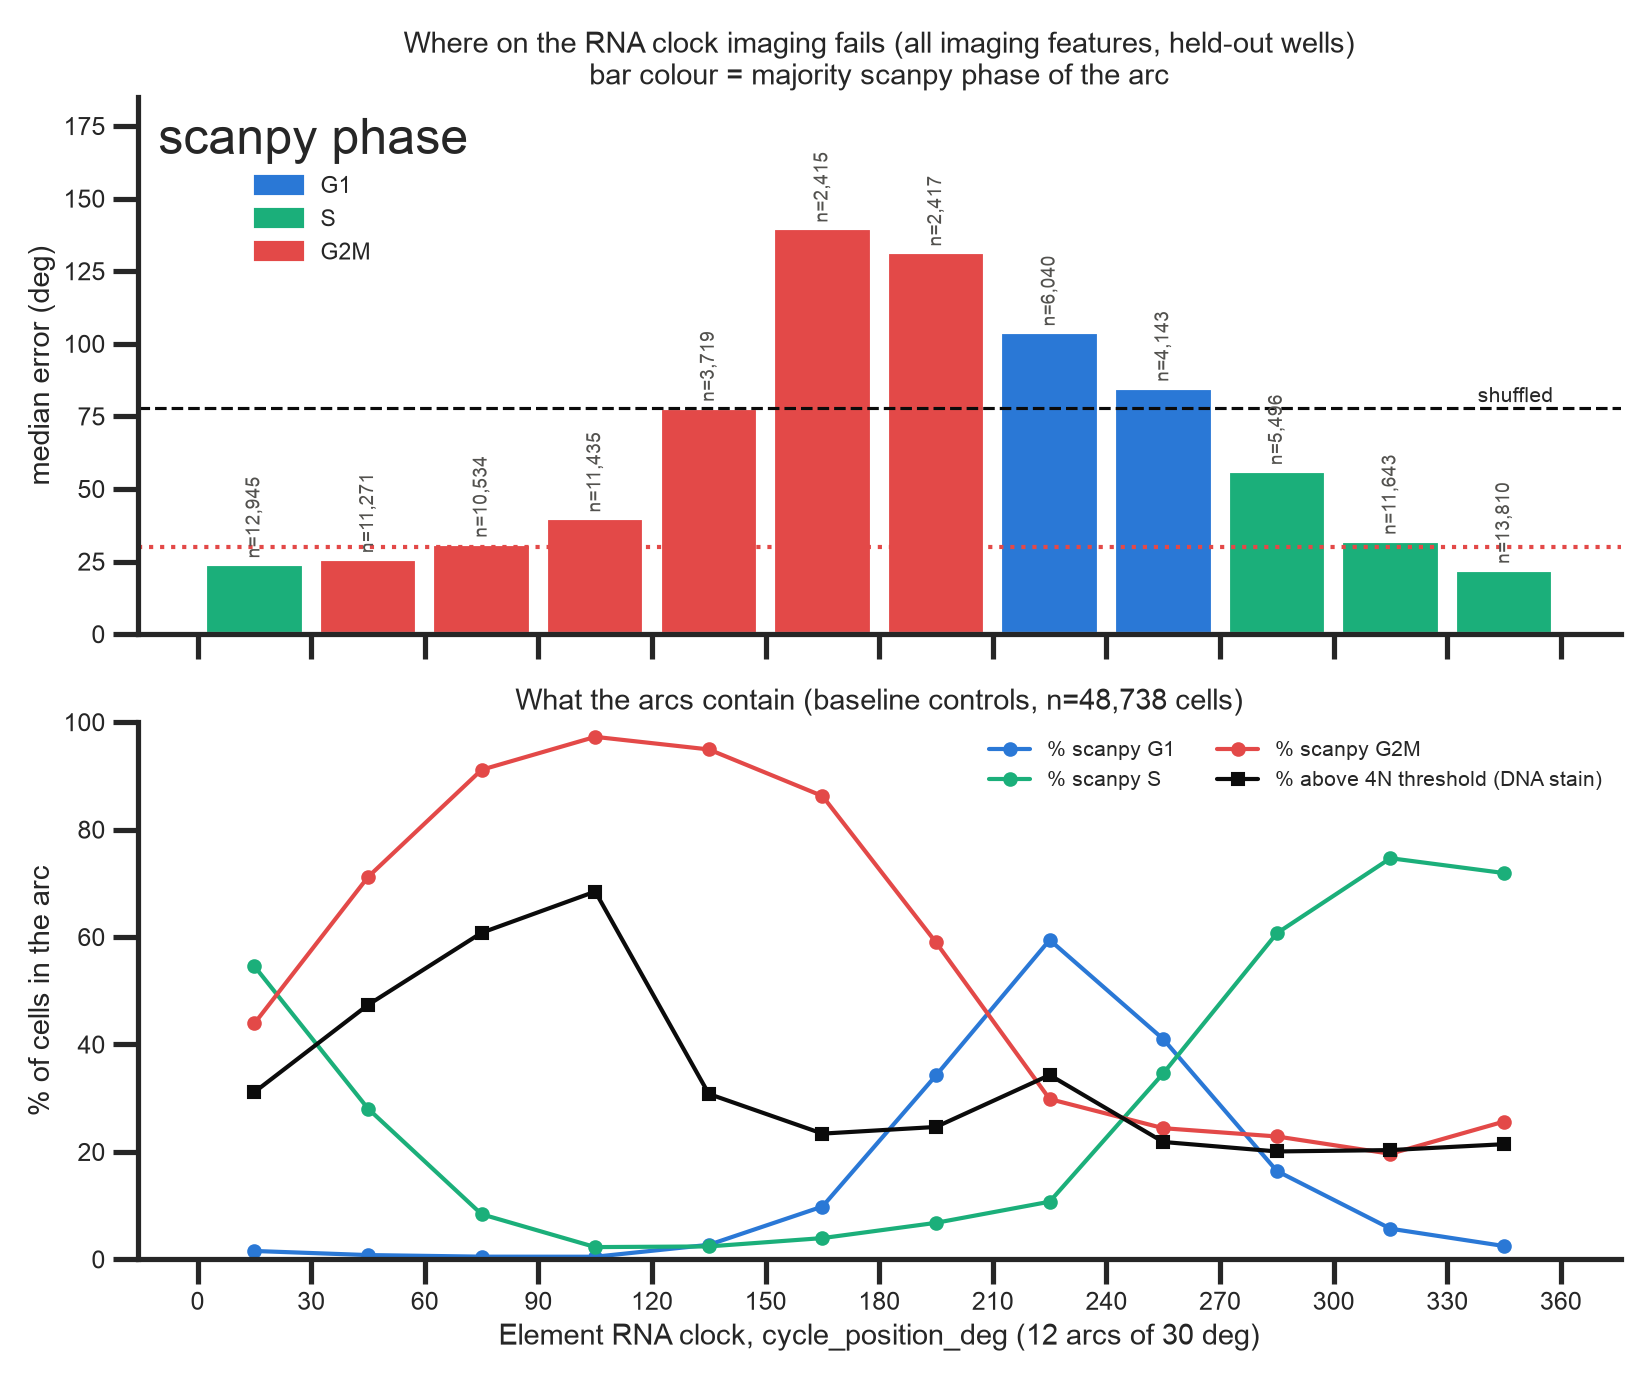

,arc_deg,median_error_deg,n_cells,majority_scanpy_phase,n_baseline_cells,pct_G1,pct_S,pct_G2M,median_dna_log2,pct_4N
0,15.0,24.1,12945,S,6395,1.5,54.6,43.9,-0.0,31.1
1,45.0,25.9,11271,G2M,5725,0.8,28.1,71.2,0.2,47.4
2,75.0,31.2,10534,G2M,5485,0.5,8.4,91.1,0.3,60.8
3,105.0,39.9,11435,G2M,5858,0.5,2.3,97.3,0.5,68.5
4,135.0,78.0,3719,G2M,1670,2.7,2.4,94.9,-0.1,30.8
5,165.0,139.7,2415,G2M,1090,9.8,3.9,86.2,-0.2,23.4
6,195.0,131.5,2417,G2M,1031,34.2,6.8,59.0,-0.2,24.6
7,225.0,104.0,6040,G1,2910,59.4,10.7,29.8,-0.1,34.3
8,255.0,84.9,4143,G1,2262,41.0,34.6,24.4,-0.2,21.8
9,285.0,56.2,5496,S,2939,16.4,60.7,22.9,-0.2,20.1


In [3]:
display(Image(filename=find('fig_A_error_by_arc.png')))
arc = pd.read_csv(find('A_error_by_clock_arc.csv')).rename(columns={'median': 'median_error_deg', 'size': 'n_cells'})
comp = pd.read_csv(find('B2_bin_composition.csv'))[['bin_deg', 'n_cells', 'pct_G1', 'pct_S', 'pct_G2M', 'median_dna_log2', 'pct_4N']]
arc.merge(comp.rename(columns={'bin_deg': 'arc_deg', 'n_cells': 'n_baseline_cells'}), on='arc_deg').round(1)

## 3. The largest reproducible cycle phenotypes

**What.** Which single features change most around the RNA clock, and are those changes reproducible?

**How.**
* **Cells.** Baseline control cells (48,738 in 6 wells).
* **Profile.** Each feature is centred on its well median and divided by its SD, then averaged in the 12 arcs of the clock.
* **Amplitude** = highest minus lowest arc mean, in SD units (how much the feature moves over the cycle).
* **Reproducibility** = Pearson r between the profiles computed in two halves of the wells (3 wells each), `split_half_r`.
* **Large and reproducible** = amplitude above 0.5 SD and split-half r above 0.9.

**Result.**
* **319 of 990 features are large and reproducible.** By family: antibodies 195 of 388, DNA stain 77 of 97, shape and size
  14 of 20, membrane 16 of 97, mitochondria 9 of 97, actin 8 of 97, **IgG 0 of 194** (median amplitude 0.08 SD, max 0.49).
  The IgG profiles are reproducible (split-half r up to 0.98) but small, as expected for a negative control.
* **Most large phenotypes peak at 120 to 150 deg**, the arc where cells divide:
  * phospho-p38 intensity and area above threshold, +1.2 to +1.4 SD (top feature: cytoplasmic p-p38 fraction above threshold, 1.31 SD amplitude);
  * phospho-ERK intensity, +1.0 SD; **phospho-ERK texture entropy** +0.5 SD (the pERK signal becomes more heterogeneous);
  * DNA-stain texture (difference entropy) +0.7 SD;
  * nuclear area -0.5 SD and cell area -0.3 SD.

  Most cells on this arc already have 2N DNA (median -0.13 log2; 31% above the loose 4N cut) while 95% still read G2M by RNA,
  so these are more likely cells that have just divided than cells in mitosis. We did not check images.
* **A second state at 210 to 240 deg** (scanpy G1-majority, newly divided cells): pERK texture becomes more uniform (entropy
  -0.6 SD, angular second moment +0.75 SD), cells and nuclei are larger (+0.6 SD), and whole-cell mitochondria and actin
  intensity rise (+0.7 to +0.8 SD, likely following cell size). We do not know why newly divided cells would be larger. One
  candidate is unsegmented daughter pairs, which would fit the small rise in cells above the 4N threshold in this arc
  (34% vs 22% in the next arc). This is not tested.
* **Caveat.** The biggest phenotypes sit in the sparsest arcs (1,031 to 2,910 cells per arc). They are reproducible between
  well halves (narrow bands in the right panel), but each arc mean rests on fewer cells.

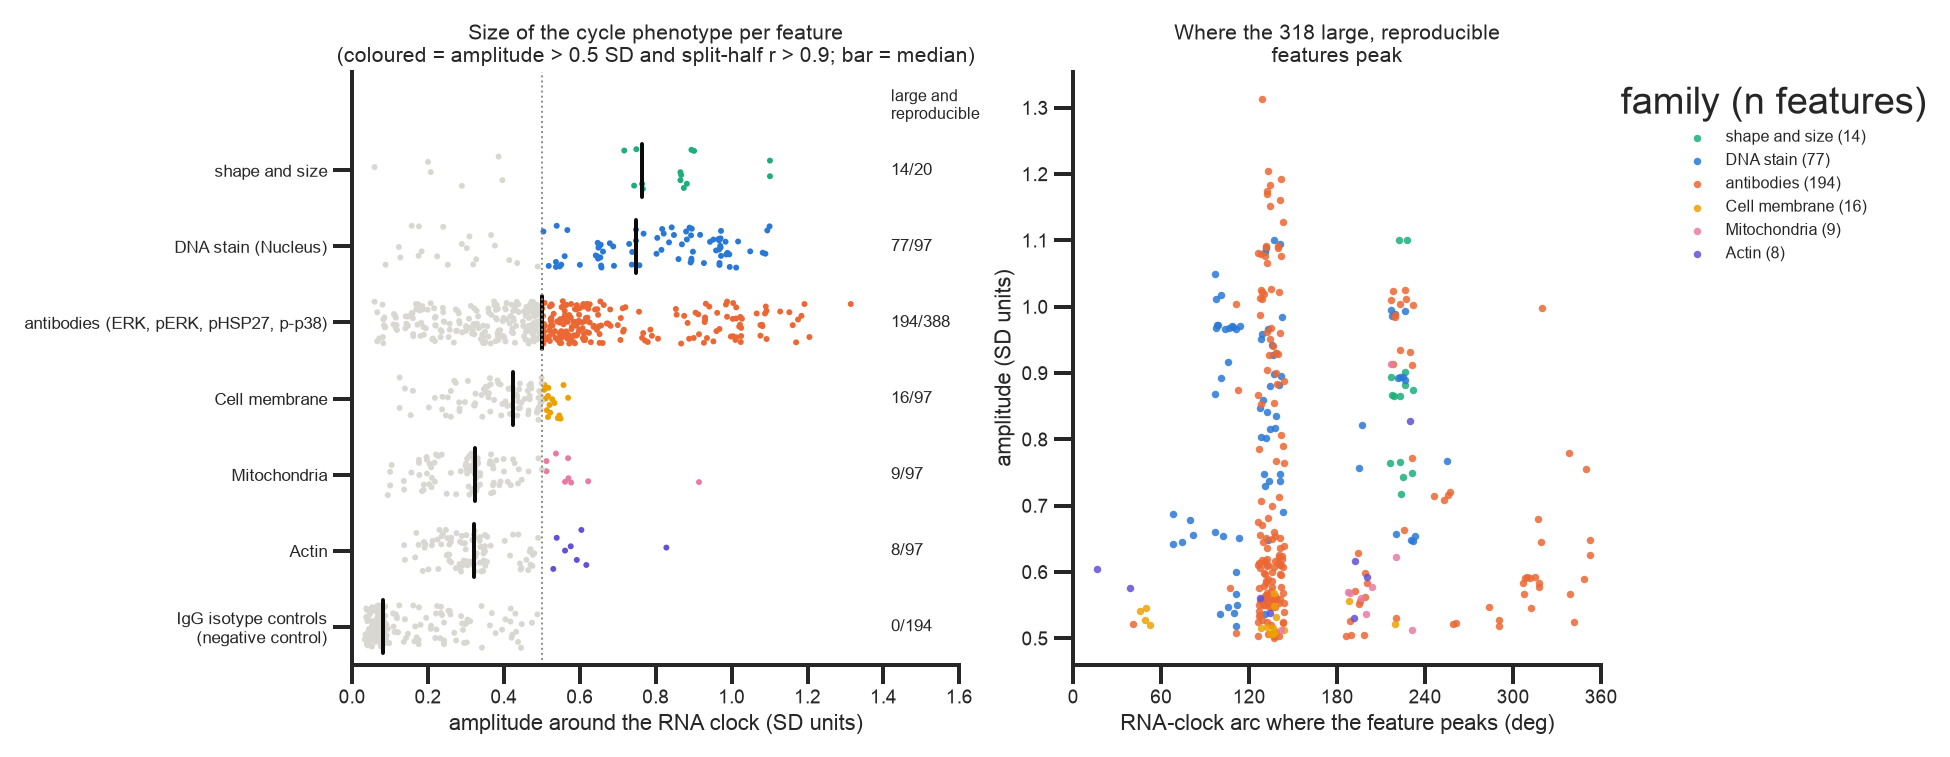

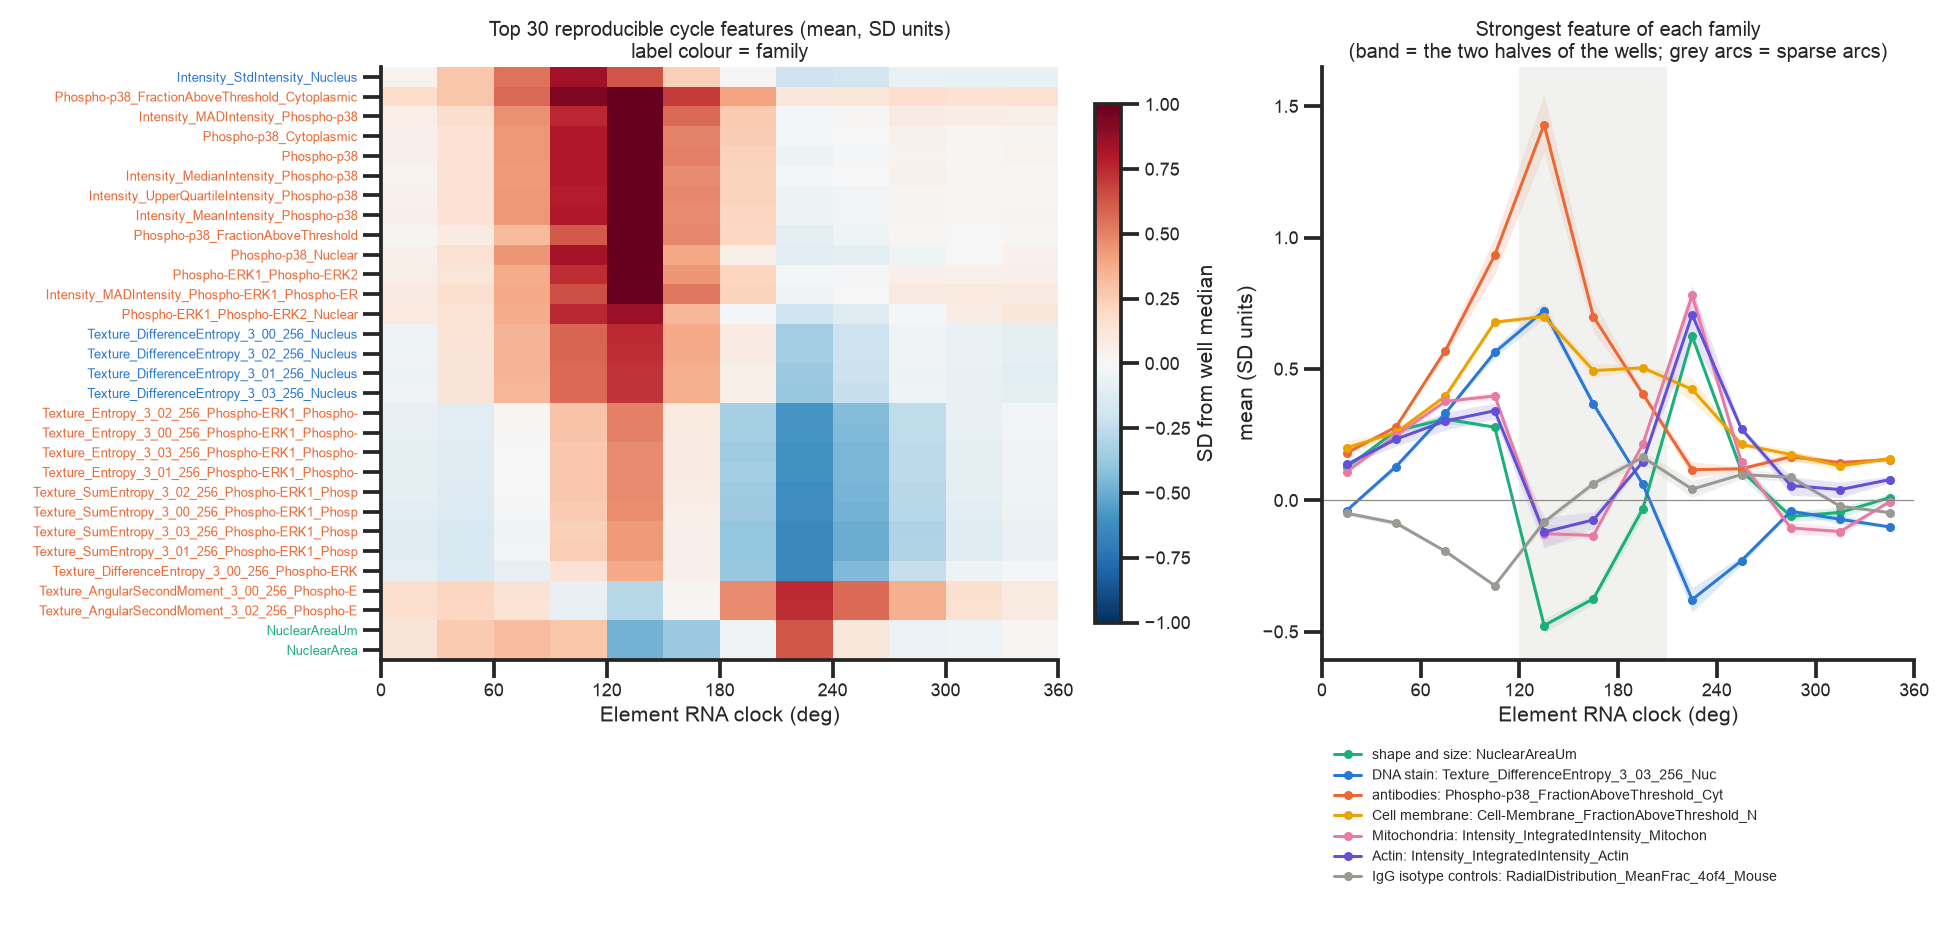

,family,n,median_amplitude_SD,max_amplitude_SD,n_reproducible_and_large
0,Actin,97,0.321,0.828,8
1,Cell membrane,97,0.423,0.569,16
2,DNA stain (Nucleus),97,0.748,1.100,77
3,IgG isotype controls (negative control),194,0.080,0.488,0
4,Mitochondria,97,0.324,0.914,9
5,"antibodies (ERK, pERK, pHSP27, p-p38)",388,0.501,1.314,195
6,shape and size,20,0.765,1.101,14


In [4]:
display(Image(filename=find('fig_B_family_amplitude.png')))
display(Image(filename=find('fig_B_profiles.png')))
pd.read_csv(find('B_family_summary.csv'))

In [5]:
B = pd.read_csv(find('B_feature_cycle_profiles.csv'))
B[(B.split_half_r > .9)].head(20)

,feature,family,amplitude_SD,peak_deg,trough_deg,split_half_r
0,Phospho-p38_FractionAboveThreshold_Cytoplasmic,"antibodies (ERK, pERK, pHSP27, p-p38)",1.314,135.0,225.0,0.996
1,Phospho-p38,"antibodies (ERK, pERK, pHSP27, p-p38)",1.205,135.0,225.0,0.994
2,Intensity_MADIntensity_Phospho-p38,"antibodies (ERK, pERK, pHSP27, p-p38)",1.192,135.0,225.0,0.995
3,Intensity_UpperQuartileIntensity_Phospho-p38,"antibodies (ERK, pERK, pHSP27, p-p38)",1.184,135.0,225.0,0.994
4,Phospho-p38_Cytoplasmic,"antibodies (ERK, pERK, pHSP27, p-p38)",1.175,135.0,225.0,0.994
5,Intensity_MedianIntensity_Phospho-p38,"antibodies (ERK, pERK, pHSP27, p-p38)",1.170,135.0,225.0,0.995
6,Intensity_MeanIntensity_Phospho-p38,"antibodies (ERK, pERK, pHSP27, p-p38)",1.161,135.0,225.0,0.995
7,Phospho-p38_FractionAboveThreshold,"antibodies (ERK, pERK, pHSP27, p-p38)",1.152,135.0,225.0,0.995
8,Phospho-p38_Nuclear,"antibodies (ERK, pERK, pHSP27, p-p38)",1.128,135.0,225.0,0.993
9,NuclearAreaUm,shape and size,1.101,225.0,135.0,0.997


## 4. Perturbations: does a morphology readout of the cycle recover real cycle shifts?

**What.** For TNFa and five knockouts, compare the cycle shift measured by the RNA clock with the shift predicted from
morphology alone.

**How.**
* **Predicted clock.** For every cell, the clock predicted from imaging by a model fit on control cells of the other wells
  (so neither the well nor the perturbed cells were seen in training).
* **Contrasts (11).** TNFa vs baseline in controls, and each knockout (CTNNB1, GSK3B, IL1R1, SMAD7, TGFBR2) vs controls in the
  same condition. n = perturbed cells (3,444 to 47,130).
* **Two shift measures.** (a) change in the percentage of cells on the G2/M-rich arc (30 to 150 deg), in percentage points;
  (b) total variation (TV) distance between the 12-arc clock distributions (0 = identical, 1 = no overlap).
  `bin_shift_corr` is the correlation between measured and predicted changes across the 12 arcs.

**Result.**
* **All measured shifts are small** (TV 0.01 to 0.10; G2/M-arc changes within 5.1 points).
* **The largest measured effect is recovered.** CTNNB1 knockout lowers the G2/M-arc share by 3.5 points (baseline) and 5.1 points (TNFa);
  morphology predicts 2.3 and 5.0.
* **There are false calls.** Morphology predicts +3.3 and +4.2 points for TGFBR2 knockout (measured -1.0 and -0.7: wrong sign)
  and +2.6 points for TNFa (measured +0.2). These perturbations change morphology in ways the model reads as cycle.
* **Across the 11 contrasts:** Spearman rho 0.59 for the G2/M-arc change (p 0.056; 0.62 over the 10 knockout contrasts), same
  sign in 8 of 11 (5 of 6 among contrasts with a measured change of at least 1 point); rho 0.79 for TV (p 0.004), but TV has
  no sign and the TGFBR2 and TNFa errors still sit well above the diagonal. Median `bin_shift_corr` 0.34.
* **Conclusion.** A morphology cycle readout tracks the size of perturbation effects (TV) but not reliably their direction
  (G2/M-arc rho not significant), and it is not specific: a perturbation
  that changes cell appearance for other reasons can look like a cycle shift. Confirm with a direct measure (DNA, RNA).

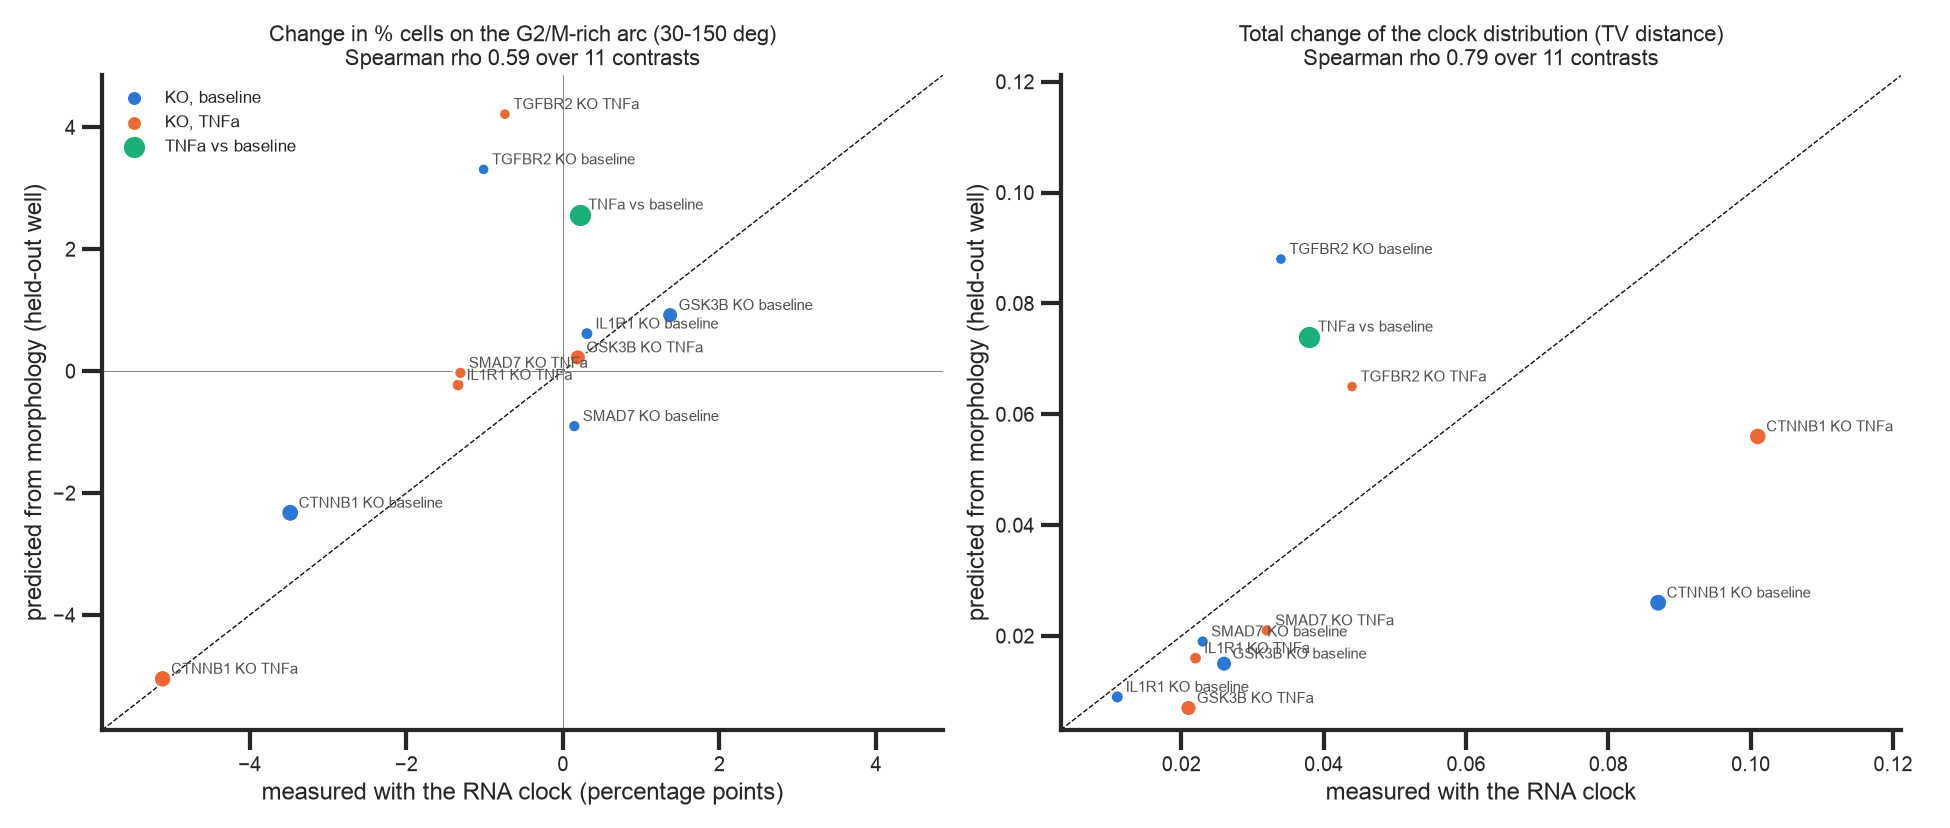

,contrast,n,measured_TV,predicted_TV,measured_d_pct_G2M_arc,predicted_d_pct_G2M_arc,bin_shift_corr
0,TNFa vs baseline (controls),47130,0.038,0.074,0.215,2.566,-0.394
1,"CTNNB1 KO vs controls, baseline",23290,0.087,0.026,-3.483,-2.324,0.268
2,"GSK3B KO vs controls, baseline",16792,0.026,0.015,1.370,0.919,0.623
3,"IL1R1 KO vs controls, baseline",7109,0.011,0.009,0.307,0.614,0.347
4,"SMAD7 KO vs controls, baseline",5115,0.023,0.019,0.146,-0.902,0.341
5,"TGFBR2 KO vs controls, baseline",3577,0.034,0.088,-1.013,3.308,-0.114
6,"CTNNB1 KO vs controls, TNFa",22058,0.101,0.056,-5.113,-5.047,0.520
7,"GSK3B KO vs controls, TNFa",17160,0.021,0.007,0.191,0.224,-0.248
8,"IL1R1 KO vs controls, TNFa",6618,0.022,0.016,-1.339,-0.227,0.345
9,"SMAD7 KO vs controls, TNFa",5060,0.032,0.021,-1.309,-0.029,0.455


In [6]:
display(Image(filename=find('fig_C_perturbations.png')))
pd.read_csv(find('C_perturbation_measured_vs_predicted.csv'))

## 5. Correlates in OPS0077

**What.** Do the cycle phenotypes seen in Element also appear in OPS0077 (A549, phase contrast plus 4i), and which OPS0077
phase-contrast features mark the same DNA states?

**How.**
* **Common axis.** OPS0077 NTC cells have no RNA clock, so both datasets are compared on measured DNA content, split into
  2N, S and 4N. Element: DNA-stain content in baseline controls, cut at 25% and 75% of the way between its 2N and 4N peaks.
  OPS0077: background-corrected DAPI (rounds 2 to 4), log2 relative to the 2N peak, cut at 0.25 and 0.75 (stricter than the
  0.65 4N cut used elsewhere in these notebooks).
* **Effect size d** = difference in means between a state and 2N, divided by the pooled SD (0.2 small, 0.5 medium, 0.8 large).
* **Shared features (65)** measured the same way in both datasets: DNA-stain Haralick texture at scale 3 (52; 13 statistics x 4
  directions), DNA-stain granularity (8), and scale-free cell shape (5: eccentricity, solidity, extent, form factor, compactness).
  For each, compare the S vs 2N and 4N vs 2N effects between datasets.
* **Phase-contrast markers.** For every OPS0077 phase-contrast feature (1,740), the same d for S vs 2N and 4N vs 2N.

**Result: shared features.**
* **DNA-stain texture agrees well.** 52 features: 4N vs 2N same sign in 94%, Spearman rho 0.67; S vs 2N same sign in 100%,
  rho 0.60. Effects are of similar size (median |d| for 4N vs 2N: 1.00 Element, 1.05 OPS0077). The 52 features are strongly
  correlated with each other (4 directions of each statistic), so the effective number of independent features is closer to 13.
* **DNA-stain granularity does not agree** (8 features: rho 0.05, same sign 62% for 4N vs 2N). Granularity is measured at
  pixel scales, and pixel size differs between the two microscopes, so the same index may not mean the same physical size.
  This is a likely reason, not tested.
* **Scale-free cell shape does not change with DNA state in either dataset** (median |d| 0.09 Element, 0.04 OPS0077). That is
  agreement on a null, not a disagreement; the sign comparison (40%) is noise around zero.
* The pooled numbers over all 65 (rho 0.78 for 4N vs 2N, 0.72 for S vs 2N) are driven by the texture features.

**Result: phase-contrast markers in OPS0077.**
* **340 of 1,740 phase features change by |d| of 0.5 or more between 4N and 2N; 66 by 0.8 or more.**
* **The strongest are intensity extremes of phase-segmented tubular and vesicular objects** (the highest per-object minimum or
  mean phase intensity in a cell, and its spread): d up to 1.64 for 4N vs 2N and about 0.8 for S vs 2N, so they rise steadily
  from 2N through S to 4N. For comparison, cell area gives d 0.74 and mean nuclear area 0.84.
* **Caveat.** "Max over objects" grows with the number of objects, which grows with cell size, and we did not adjust these
  features for size. They read as "more and optically denser material in larger cells", which is what phase contrast
  measures (dry mass), rather than a specific organelle change.
* **Link to Element.** Element has no phase contrast, so the two datasets meet only through the shared DNA-stain texture.
  There, the same 2N to S to 4N changes appear in both, which supports reading the Element imaging cycle signal and the
  OPS0077 DNA axis as the same biology.

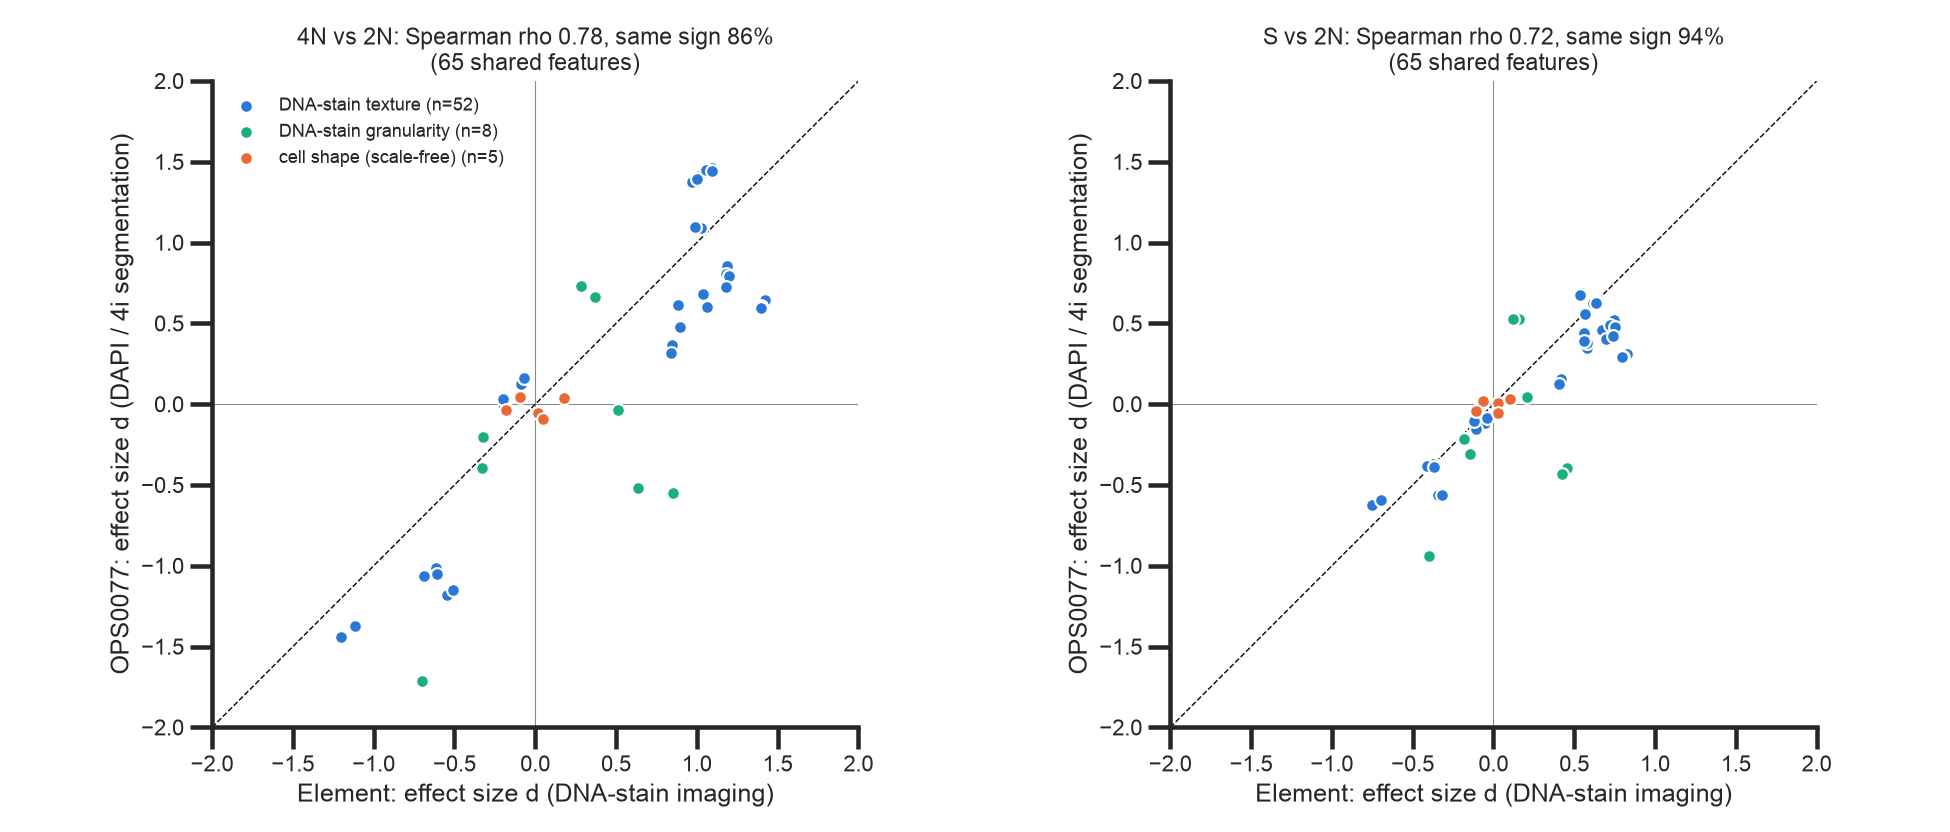

,kind,contrast,n_features,spearman_rho,spearman_p,pct_same_sign,median_abs_d_element,median_abs_d_ops
0,all shared,S vs 2N,65,0.72,1.700000e-11,94.0,0.54,0.39
1,all shared,4N vs 2N,65,0.78,1.900000e-14,86.0,0.97,0.73
2,DNA-stain granularity,S vs 2N,8,0.06,8.900000e-01,75.0,0.19,0.42
3,DNA-stain granularity,4N vs 2N,8,0.05,9.100000e-01,62.0,0.44,0.53
4,DNA-stain texture,S vs 2N,52,0.60,2.500000e-06,100.0,0.57,0.41
5,DNA-stain texture,4N vs 2N,52,0.67,5.400000e-08,94.0,1.00,1.05
6,cell shape (scale-free),S vs 2N,5,0.50,3.900000e-01,60.0,0.06,0.03
7,cell shape (scale-free),4N vs 2N,5,-0.20,7.500000e-01,40.0,0.09,0.04


In [7]:
display(Image(filename=find('fig_D_shared_features.png')))
pd.read_csv(find('D_summary_by_kind.csv'))

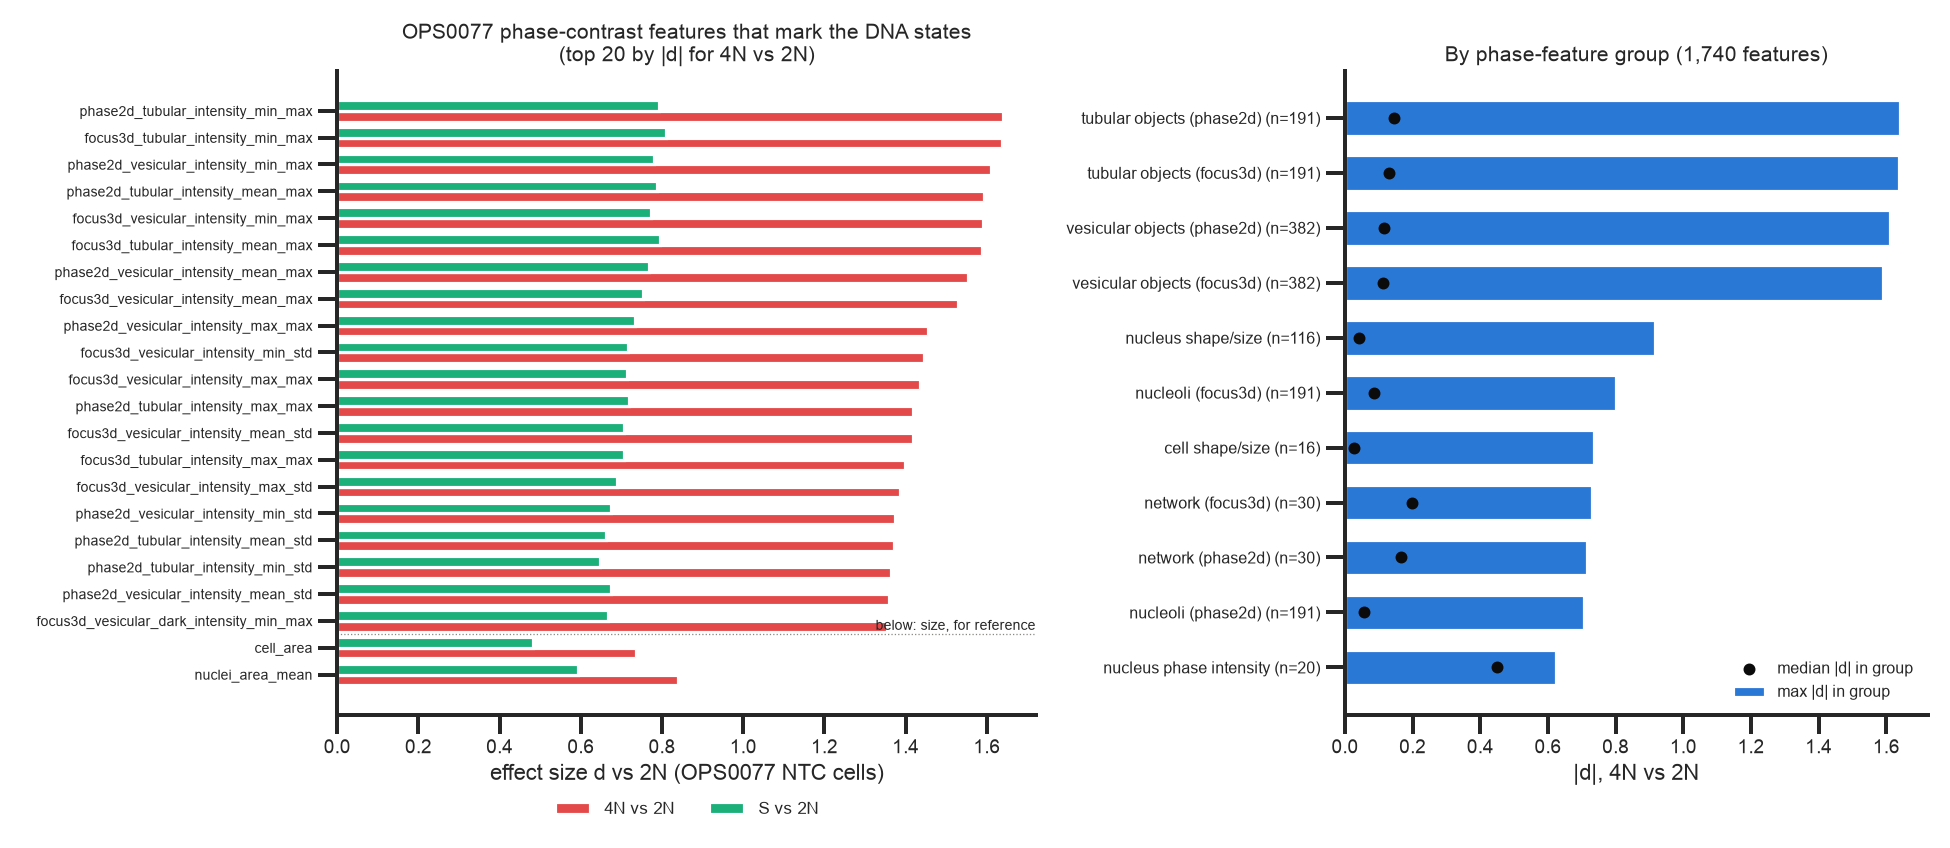

,group,n_features,median_abs_d_4N,max_abs_d_4N,n_abs_d_4N_ge_0_8
0,tubular objects (phase2d),191,0.145,1.640,11
1,tubular objects (focus3d),191,0.131,1.638,11
2,vesicular objects (phase2d),382,0.115,1.610,17
3,vesicular objects (focus3d),382,0.112,1.590,21
4,nucleus shape/size,116,0.042,0.917,5
5,nucleoli (focus3d),191,0.085,0.801,1
6,cell shape/size,16,0.026,0.735,0
7,network (focus3d),30,0.198,0.731,0
8,network (phase2d),30,0.165,0.716,0
9,nucleoli (phase2d),191,0.055,0.707,0


,S_vs_2N,4N_vs_2N,abs_4N
op_phase2d_tubular_intensity_min_max,0.792,1.640,1.640
op_focus3d_tubular_intensity_min_max,0.809,1.638,1.638
op_phase2d_vesicular_intensity_min_max,0.781,1.610,1.610
op_phase2d_tubular_intensity_mean_max,0.787,1.592,1.592
op_focus3d_vesicular_intensity_min_max,0.772,1.590,1.590
op_focus3d_tubular_intensity_mean_max,0.796,1.589,1.589
op_phase2d_vesicular_intensity_mean_max,0.769,1.554,1.554
op_focus3d_vesicular_intensity_mean_max,0.754,1.530,1.530
op_phase2d_vesicular_intensity_max_max,0.734,1.454,1.454
op_focus3d_vesicular_intensity_min_std,0.715,1.445,1.445


In [8]:
display(Image(filename=find('fig_D_phase_markers.png')))
display(pd.read_csv(find('D_phase_family_summary.csv')))
pd.read_csv(find('D_ops0077_phase_features_by_dna_state.csv'), index_col=0).head(15)

## Takeaways

1. **Element imaging reads the RNA cell-cycle clock to 37.5 degrees (median, held-out wells, 95,868 control cells).** The DNA
   stain carries most of the signal; the phospho-antibody panel adds some. Mitochondria, membrane, actin and shape do no better
   than IgG isotype controls, so they add nothing beyond nonspecific signal.
2. **The RNA clock and morphology disagree around division** (135 to 255 deg, 19.5% of cells). There the RNA still says G2/M
   or early G1 while the DNA is already 2N, and imaging places these cells with other 2N cells. Morphology and transcriptome
   see the same cycle except for this post-division stretch.
3. **The largest reproducible morphological cycle phenotypes are at division**: phospho-p38 and phospho-ERK intensity, pERK
   texture entropy and DNA-stain texture rise and nuclei shrink at 120 to 150 deg; at 210 to 240 deg pERK texture becomes more
   uniform and cells are larger. Both arcs are sparse; the first fits just-divided cells (2N DNA, G2M RNA), and the second is unexplained.
4. **A morphology-predicted cycle recovers the strongest perturbation (CTNNB1 knockout) but gives false shifts for TGFBR2
   knockout and TNFa.** It ranks the size of shifts (TV rho 0.79, p 0.004, 11 contrasts), not their direction; check with DNA or RNA.
5. **The DNA-stain texture changes from 2N to S to 4N reproduce in OPS0077** (same sign in 94% of 52 features). Granularity
   does not transfer between the two microscopes. In OPS0077, the best phase-contrast markers of DNA state are intensity
   extremes of phase-segmented objects (d up to 1.64), stronger than cell area alone (0.74) but not size-adjusted.